In [27]:
import os
import sys 
print("Active Environment Path:", sys.executable)
from pathlib import Path
import json
import subprocess
import importlib
import tempfile

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, PrecisionRecallDisplay
import shapely

import pystac_client
import planetary_computer
import odc.stac
import rasterio.features

# local
os.chdir("/home/azureuser/EBRD_Tillage/AK_Experiments/AK_pipeline")
sys.path.append(os.getcwd())
from Generic.addSentinelIndices import calculateSentinelIndex, SENTINEL_INDEX_DEPENDENCIES
from utils.classify_tillage import classify_tillage
from ml.nominal_classification import RFC 

Active Environment Path: /anaconda/envs/geospatial-base/bin/python


In [28]:
# ==============================================================================
# 1. HELPER FUNCTIONS FOR IN-MEMORY STAC & RASTER REDUCTION
# ==============================================================================
def check_xarray_nan(obj):
    if isinstance(obj, xr.Dataset):
        return False
    elif pd.isna(obj):  # Handles float('nan'), np.nan, and None safely
        return True
    else:
        raise 

    
# This needn't be called for every fields, I am calling it for a sample field. 
def get_utm_crs(gdf: gpd.GeoDataFrame) -> str:
    """Determine the local UTM EPSG code from a GeoDataFrame centroid."""
    centroid = gdf.to_crs("EPSG:4326").union_all().centroid
    lon, lat = centroid.x, centroid.y
    zone = int((lon + 180) // 6) + 1
    epsg = 32600 + zone if lat >= 0 else 32700 + zone
    return f"EPSG:{epsg}"

#########################################################33    
def get_sentinel1_STAC(
        geom: shapely.geometry,
        catalog_client: pystac_client.Client,
        utm_crs: str, 
        input_bands :list, 
        start : str,
        end: str, 
        resolution: float = 10.0,
        orbit_direction: str = None,  # Optional: "ascending" or "descending"
):
    """Stream optical bands for a single event directly into memory and return
                Object stored as Xarray Dataset. 
                Xarray is 3 dimentions with x y and time, with '4th dimension' being bands. 
        """
    # 2. Prepare STAC query filters (No cloud cover filter for SAR)
    query_params = {}

    if orbit_direction in ["ascending", "descending"]:
        query_params["sat:orbit_state"] = {"eq": orbit_direction}

    # 3. STAC Search directly in memory
    search = catalog_client.search(
        collections=["sentinel-1-rtc"],
        intersects=geom.__geo_interface__,
        datetime=f"{start}/{end}",
        query=query_params if query_params else None,
        limit=100,
    )
    items = list(search.items())

    if not items:
        return np.nan

    # Sign asset URLs for Planetary Computer Azure SAS authentication
    items = [planetary_computer.sign(item) for item in items]

    # 4. Project polygon to local UTM for accurate 10m spatial rasterization
    event_gdf = gpd.GeoDataFrame(geometry=[geom], crs="EPSG:4326") 
    event_utm = event_gdf.to_crs(utm_crs)
    minx, miny, maxx, maxy = event_utm.total_bounds
    
     
    # 5. Load Sentinel-1 backscatter assets into memory using odc.stac
    xarray_ds = odc.stac.load(
        items,
        bands=input_bands,  # Usually ['vv', 'vh']
        crs=utm_crs,
        resolution=resolution,
        x=(minx - 20, maxx + 20),
        y=(miny - 20, maxy + 20),
        chunks={},
    ).load()  # Materialize arrays into RAM

    if xarray_ds.sizes.get("time", 0) == 0:
        return np.nan
    #print("Min ",np.array(xarray_ds['vv']).min()," Mean  ",np.array(xarray_ds['vv']).mean())
    # Convert linear amplitude values to float32
    for rawband in list(xarray_ds.data_vars): 
            xarray_ds[rawband] = xarray_ds[rawband].astype("float32")
            xarray_ds[rawband] = xarray_ds[rawband].where(xarray_ds[rawband] > -50.0)

    return xarray_ds
######################################################################################################
def get_sentinel2_STAC(
        geom: shapely.geometry,
        catalog_client: pystac_client.Client, 
        utm_crs: str, 
        input_bands :list, 
        start : str,
        end: str, 
        max_cloud_cover: int = 90,
        resolution: float = 10.0,
    ):
    """Stream optical bands for a single event directly into memory and return
            Object stored as Xarray Dataset. 
            Xarray is 3 dimentions with x y and time, with '4th dimension' being bands. 
    """

    # 2. STAC Search directly in memory
    search = catalog_client.search(
        collections=["sentinel-2-l2a"],
        intersects=geom.__geo_interface__,
        datetime=f"{start}/{end}",
        query={"eo:cloud_cover": {"lte": max_cloud_cover}},
        limit=100
        )
    items = list(search.items())
    if not items:
            return np.nan
    # Sign asset URLs for Planetary Computer Azure SAS authentication
    items = [planetary_computer.sign(item) for item in items]

    # 3. Project polygon to local UTM for accurate 10m spatial rasterization
    event_gdf = gpd.GeoDataFrame(geometry=[geom], crs="EPSG:4326")
    event_utm = event_gdf.to_crs(utm_crs)
    minx, miny, maxx, maxy = event_utm.total_bounds
    ####width, height, area = maxx-minx , maxy-miny , event_utm.geometry.area.iloc[0]/1_000_000 
    ####print("Width, Height -- ", width,height,"Area -- ",area)
    # 4. Calculate required bands and stream  directly into an xarray DataArray
    # (xarray chunks/streams directly from Azure Blob Storage COGs)
    xarray_ds = odc.stac.load(
        items,
        bands=input_bands,
        crs=utm_crs,
        resolution=resolution,
        x=(minx - 20, maxx + 20),
        y=(miny - 20, maxy + 20),
        chunks={}
    ).load() # Materialize arrays into RAM

    if xarray_ds.sizes.get("time", 0) == 0:
        return np.nan
        
    # 5. Apply ESA baseline offset correction if needed (>4000 DN)
    for rawband in list(xarray_ds.data_vars): 
        xarray_ds[rawband] = xarray_ds[rawband].astype("float32")

    return xarray_ds
    
    


In [29]:
def generate_indices(xarray_ds,bands,utm_crs, temp_aggregations = ['min'], space_aggregations = ['mean'] ):
    '''
    From an Xarray with satellite data, get dataframe with indices. 

    Xarray is 3 dimentions with x y and time, with '4th dimension' being bands. 
    Index calculation is point wise, which means it only adds to the bands. 
    The bands (data_vars) are callable with names, so the function behaves exactly like a dataframe. 
        
    The pipeline of 1.Temporal Aggregation 2. Rasterization and 3. Spatial Aggregation is best. 
    
    '''
    event_gdf = gpd.GeoDataFrame(geometry=[geom], crs="EPSG:4326")
    event_utm = event_gdf.to_crs(utm_crs) # for rasterizing
    
    #6. Calculate Indices, Temporal Aggregate, and Spatial Aggregate 
    time_aggregate_mapping = {
                #Arg is not a good idea. We don't know what the start and end dates are and what they represent. 
                'min': lambda x: x.min(dim="time"),
                'mean': lambda x: x.mean(dim = "time") ,
                'median': lambda x: x.median(dim = 'time'),
                'max':lambda x: x.max(dim="time")
            }
    space_aggregate_mapping = {
        'mean': lambda x:  np.nanmean(x),
        'min': lambda x:  np.nanmin(x),
        'median': lambda x:  np.nanmedian(x),
        'max': lambda x:  np.nanmax(x)
                }
    
    transform = xarray_ds.odc.transform
    height, width = xarray_ds.sizes["y"], xarray_ds.sizes["x"]
    final_dict = {} 
    for band in bands: 
        #final_t_s = calculateSentinelIndex(xarray_ds[SENTINEL_INDEX_DEPENDENCIES[band]] , band)[band] #This saves memory ( I think?)
        final_t_s = calculateSentinelIndex(xarray_ds , band)[band] #This saves memory ( I think?)
        # Band_t_s is now 3D 
        append = band
        for tempAg in temp_aggregations: 
            final_s  = time_aggregate_mapping[tempAg](final_t_s) 
            #Band_s is now 2D, and it needs to be rasterized first to remove pixels outside boundary. 
            # 7. Rasterizing each band. 
            mask = rasterio.features.rasterize(
                    [(geom, 1) for geom in event_utm.geometry],
                    out_shape=(height, width),
                    transform=transform,
                    fill=0,
                    dtype="uint8"
                )
            final_s_masked = np.where(mask == 1, final_s.values, np.nan)

            append += '__'+tempAg
            # 8. Spatial Aggregation
            for spatAg in space_aggregations:
                final =  space_aggregate_mapping[spatAg](final_s_masked)
                # Finally, this is a single value. 
                append += '__'+spatAg
                final_dict[append]  = float(final)
    return final_dict
    

1. Aggregations need to happen for raw bands too
2. 

In [30]:

RUN_ACQUIRE_PATH = Path("/home/azureuser/EBRD_Tillage/EBRD_tillage_monitoring-main/src/acquire/run_acquire.py")  
TEMP_DIR = Path("/home/azureuser/EBRD_Tillage/data/temp")
TEMP_DIR.mkdir(parents=True, exist_ok=True)
INPUT_DATA_PATH= Path("/home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp")  

# Global Variables 
stratified_limitation =-1
buffer_days = 5
resolution = 10
target_to_use = 'Nominal' # Options -- baseline (Classifica column), baseline_other(other class included), 
                                            # alex , alex_binary ,
                                            # Nominal, 
                                            # [NOT IMPELEMETD => ]
                                            ## Alex sustainability Score 
                                            #### This is currently approximate. In depth feature extraction with given depth, turnover etc need to be considered. 
use_saved = False # If selected, MPC will not be called and MLDF will be selected from saved local storage. 


kind = 'Sentinel2' # Kinda useless now, only Sentinel 2 in VM
bands_s2 = ['NDVI','NDTI','STI']
padding = 5
tempAg = ['min','mean','median']
spatAg = ['mean','median']
max_cloud_cover = 90
get_all_raw_bands_s2 = False 

use_raw_bands_also = True

if(get_all_raw_bands_s2): 
    input_bands_s2 = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12", "SCL"]
else: 
    input_bands_s2 = []
    for band in bands_s2: 
        input_bands_s2 += SENTINEL_INDEX_DEPENDENCIES[band]
    input_bands_s2 = list(set(input_bands_s2))

input_bands_s1 = ['vh','vv']
bands_s1 = ['vvvh']

total_bands_s2 = input_bands_s2 + bands_s2 if use_raw_bands_also else bands_s2
total_bands_s1 = input_bands_s1 + bands_s1 if use_raw_bands_also else bands_s1

In [31]:
# ==============================================================================
# 1. SETUP & PATH CONFIGURATION
# ==============================================================================
print(f"Reading shapefile from: {INPUT_DATA_PATH}")
gdf = gpd.read_file(INPUT_DATA_PATH).drop(columns = ['index'])
gdf=gdf.to_crs("EPSG:4326")
# Quick check
print(f"Successfully loaded {len(gdf)} rows.")
gdf = gdf.rename(columns={'Beginning':'start_date',"End date":'end_date'})
print(gdf.columns)
gdf["start_date"] = pd.to_datetime(gdf["start_date"])
gdf["end_date"] = pd.to_datetime(gdf["end_date"])

gdf = classify_tillage(gdf,target_to_use)


if(stratified_limitation>0 and (not use_saved)): 
    lis = []
    for name,group in gdf.groupby('Target'): 
        if(group.shape[0] < stratified_limitation): 
            lis.append(group)
        else:
            lis.append(group.sample(stratified_limitation))
        print(sum(df.shape[0] for df in lis))
    gdf = pd.concat(lis).reset_index(drop=True)
print(f"Filtered to {len(gdf)} rows.")


catalog_client = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=planetary_computer.sign_inplace
    )
sample_gdf = gdf.sample()
utm_crs = get_utm_crs(sample_gdf)
## the entire gdf should not be changed here. Something about the catalog expects 4236, I haven't checked. 



Reading shapefile from: /home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp
Successfully loaded 5746 rows.
Index(['fid', 'Operation', 'Group of o', 'Machinery', 'Machine', 'start_date',
       'end_date', 'Field ID', 'Crop', 'Year', 'Area, ha', 'operation_',
       'source_fil', 'FieldAreaH', 'Completion', 'Classifica', 'geometry'],
      dtype='str')
Filtered to 5746 rows.


In [ ]:
# ==============================================================================
# 2.0 CHUNKING FOR MPC CALL
# ==============================================================================
def chunk_df(df, column_name, target_chunk_size):
    """
    Adds '_chunk_bin' and 'chunk_num' columns based on equal-frequency
    quantile binning of a target column.
    """
    df = df.copy()

    # Determine required number of bins
    num_chunks = int(np.ceil(len(df) / target_chunk_size))

    # Assign equal-frequency quantile intervals
    df["_chunk_bin"] = pd.qcut(df[column_name], q=num_chunks, duplicates="drop")

    # Assign integer chunk numbers (0, 1, 2, ...) ordered by the bin intervals
    df["chunk_num"] = df["_chunk_bin"].cat.codes

    return df

gdf_utm = gdf.to_crs(utm_crs)
areas = gdf_utm.geometry.area.sort_values().reset_index(drop=True)
areas = areas.apply(lambda x: x/1_000_000)
#aspect_ratios_x = (gdf_utm.geometry.bounds.apply(lambda b: (b.maxx - b.minx) / (b.maxy - b.miny), axis=1)).sort_values().reset_index(drop=True)
#aspect_ratios_y = (gdf_utm.geometry.bounds.apply(lambda b: (b.maxy - b.miny) / (b.maxx - b.minx), axis=1)).sort_values().reset_index(drop=True)
#elongation = [max(aspect_ratios_x[i],aspect_ratios_y[i]) for i in range(len(areas))]
heights = (gdf_utm.geometry.bounds.maxy - gdf_utm.geometry.bounds.miny).sort_values().reset_index(drop=True)
widths = (gdf_utm.geometry.bounds.maxx - gdf_utm.geometry.bounds.minx).sort_values().reset_index(drop=True)

gdf_utm['heights'] = heights 
gdf_utm['widths'] = widths 
gdf_utm['areas'] = areas

gdf_chunked_utm = chunk_df(gdf_utm, 'areas', 200) #[['chunk_num','_chunk_bin']]
gdf_chunked = gdf.copy() 
gdf_chunked['chunk_num'] = gdf_chunked_utm['chunk_num']
gdf_chunked['_chunk_bin'] = gdf_chunked_utm['_chunk_bin']
gdf_chunked['heights_utm'] = gdf_chunked_utm['heights']
gdf_chunked['widths_utm'] = gdf_chunked_utm['widths']
gdf_chunked['areas_utm'] = gdf_chunked_utm['areas']

del gdf_chunked_utm 

## FINDING THE RIGHT SIZES 
df_lis = []
for num, grp in gdf_chunked.groupby('chunk_num'): 
    maxi = grp[["heights_utm", "widths_utm", "areas_utm"]].idxmax().unique()
    #maxi = grp[["heights"]].idxmax().unique()
    df = grp.loc[maxi]
    df['chunk_num'] = num 
    df_lis.append(df)

max_df = pd.concat(df_lis,ignore_index=True)
MAX_TARGETS_X_Y = { #Unprojected. 
    1 : (143, 161),
    2: (216,327),  
    3: (288, 327)
}
gdf_chunked['_chunk_bin'].value_counts() , max_df.chunk_num.value_counts().value_counts()

(_chunk_bin
 (1.538, 1.594]    242
 (1.479, 1.505]    240
 (2.041, 2.316]    237
 (0.985, 1.03]     233
 (2.451, 2.597]    229
 (1.262, 1.332]    227
 (1.918, 1.967]    224
 (2.984, 3.681]    224
 (0.794, 0.958]    221
 (1.372, 1.449]    218
 (1.967, 2.036]    215
 (3.681, 4.255]    214
 (1.195, 1.235]    213
 (1.119, 1.195]    211
 (1.749, 1.918]    203
 (0.958, 0.985]    195
 (1.235, 1.262]    187
 (2.316, 2.394]    186
 (1.594, 1.64]     184
 (1.03, 1.064]     178
 (1.449, 1.479]    176
 (1.64, 1.749]     176
 (2.597, 2.984]    174
 (1.064, 1.119]    172
 (1.332, 1.372]    158
 (1.505, 1.538]    155
 (2.394, 2.451]    154
 (2.036, 2.041]    153
 (4.255, 5.896]    147
 Name: count, dtype: int64,
 count
 3    27
 2     2
 Name: count, dtype: int64)

In [ ]:

[[0, ('X', 153, 'Y', 140), ('X', 131, 'Y', 161)],
 [1, ('X', 185, 'Y', 144), ('X', 130, 'Y', 177), ('X', 130, 'Y', 177)],
 [2, ('X', 357, 'Y', 147)],
 [3, ('X', 159, 'Y', 193), ('X', 394, 'Y', 171)],
 [4, ('X', 242, 'Y', 93)],
 [5, ('X', 423, 'Y', 224), ('X', 423, 'Y', 224), ('X', 423, 'Y', 224)],
 [6, ('X', 259, 'Y', 118), ('X', 259, 'Y', 118), ('X', 259, 'Y', 118)],
[7, ('X', 231, 'Y', 89), ('X', 231, 'Y', 89), ('X', 231, 'Y', 89)],
 [8, ('X', 344, 'Y', 146), ('X', 220, 'Y', 186), ('X', 344, 'Y', 146)],
 [9, ('X', 171, 'Y', 151), ('X', 171, 'Y', 151), ('X', 143, 'Y', 168)],
 [10],
 [11, ('X', 281, 'Y', 226), ('X', 183, 'Y', 152), ('X', 183, 'Y', 152)],
 [12, ('X', 170, 'Y', 139), ('X', 146, 'Y', 132)],
 [13, ('X', 208, 'Y', 217), ('X', 208, 'Y', 217), ('X', 208, 'Y', 217)],
 [14, ('X', 143, 'Y', 119), ('X', 130, 'Y', 161)],
 [15, ('X', 253, 'Y', 197), ('X', 194, 'Y', 104), ('X', 194, 'Y', 104)],
 [16, ('X', 275, 'Y', 186), ('X', 275, 'Y', 186), ('X', 275, 'Y', 186)],
 [17, ('X', 168, 'Y', 135), ('X', 202, 'Y', 155), ('X', 202, 'Y', 155)],
 [18, ('X', 166, 'Y', 161), ('X', 183, 'Y', 224), ('X', 166, 'Y', 161)],
 [19, ('X', 229, 'Y', 211), ('X', 229, 'Y', 211), ('X', 229, 'Y', 211)],
 [20, ('X', 148, 'Y', 131), ('X', 183, 'Y', 129)],
 [21, ('X', 338, 'Y', 294)],
 [22, ('X', 204, 'Y', 108), ('X', 204, 'Y', 108), ('X', 204, 'Y', 108)],
 [23, ('X', 216, 'Y', 327), ('X', 216, 'Y', 327), ('X', 212, 'Y', 99)],
 [24, ('X', 318, 'Y', 102), ('X', 286, 'Y', 335), ('X', 318, 'Y', 102)],
 [25],
 [26, ('X', 156, 'Y', 149), ('X', 168, 'Y', 133), ('X', 181, 'Y', 206)],
 [27, ('X', 256, 'Y', 102), ('X', 146, 'Y', 141)],
 [28, ('X', 288, 'Y', 243), ('X', 288, 'Y', 243)]]

In [51]:
# ==============================================================================
# 2.1 GET DATA FROM MPC 
# ==============================================================================
from azure.identity import DefaultAzureCredential
from azure.ai.ml import MLClient
import fsspec
import zarr
def get_data_from_mpc(catalog_client, gdf , target_x, target_y, utm_crs): 
    """
    This function uses a Sentinel 2.
    """
    print(f"Starting in-memory processing for {len(gdf)} tillage events...")
    TARGET_CRS = utm_crs
    feature_datasets = []
    valid_feature_ids = []
    # Run in-memory extraction over events
    band_results = []
    for idx, row in gdf.iterrows():
        index = {'fid_key':row['fid']}
        geom  = row['geometry']
        #start_dt = (pd.to_datetime(row["start_date"]) - pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
        start = pd.to_datetime(row["end_date"]).strftime("%Y-%m-%d")
        end = (pd.to_datetime(row["end_date"]) + pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
        print(f"Processing Event {idx+1}/{len(gdf)}: {row['fid']}",end="")
        xarray_ds_s2 = get_sentinel2_STAC(geom, catalog_client,utm_crs,input_bands_s2, start,end, max_cloud_cover=90,resolution =10)
        #xarray_ds_s1 = get_sentinel1_STAC(geom, catalog_client, utm_crs, input_bands_s1, start, end, resolution = 10, orbit_direction = None)
        if not check_xarray_nan(xarray_ds_s2):
                current_y, current_x = xarray_ds_s2.sizes["y"], xarray_ds_s2.sizes["x"]
                if(current_y > target_y or current_x > target_x):
                    raise Exception(f'Target x or Y need to be larger: Current x y- {current_x} , {current_y}; Target x,y -- {target_x} , {target_y}')
                print('Current y,x -- ', current_y,current_x)
                pad_y = max(0, target_y - current_y)
                pad_x = max(0, target_x - current_x)
                if pad_y > 0 or pad_x > 0:
                    xarray_ds_s2 = xarray_ds_s2.pad(
                        y=(0, pad_y),
                        x=(0, pad_x),
                        constant_values=xarray_ds_s2['B04'].attrs.get("nodata", 0))
                # Trim to exact target spatial dimensions
                xarray_ds_s2 = xarray_ds_s2.isel(y=slice(0, target_y), x=slice(0, target_x))
                xarray_ds_s2 = xarray_ds_s2.assign_coords(y=np.arange(target_y), x=np.arange(target_x))
                # Trigger compute for the individual polygon raster block
                xarray_ds_s2 = xarray_ds_s2.compute()
                feature_datasets.append(xarray_ds_s2)
                valid_feature_ids.append(row['fid'])
                print("Feature Appended")

    # 4. Concatenate feature datasets along the 'feature_id' dimension
    ds_cube = xr.concat(feature_datasets, dim="feature_id")
    ds_cube["feature_id"] = valid_feature_ids
    return ds_cube 

def find_max_limits(catalog_client, gdf , utm_crs): 
    """
    This function uses a Sentinel 2.
    """
    print(f"Starting in-memory processing for {len(gdf)} tillage events...")
    TARGET_CRS = utm_crs
    feature_datasets = []
    valid_feature_ids = []
    # Run in-memory extraction over events
    band_results = []
    for idx, row in gdf.iterrows():
        index = {'fid_key':row['fid']}
        geom  = row['geometry']
        #start_dt = (pd.to_datetime(row["start_date"]) - pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
        start = pd.to_datetime(row["end_date"]).strftime("%Y-%m-%d")
        end = (pd.to_datetime(row["end_date"]) + pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
        print(f"Processing Event {idx+1}/{len(gdf)}: {row['fid']}",end="")
        xarray_ds_s2 = get_sentinel2_STAC(geom, catalog_client,utm_crs,input_bands_s2, start,end, max_cloud_cover=90,resolution =10)
        #xarray_ds_s1 = get_sentinel1_STAC(geom, catalog_client, utm_crs, input_bands_s1, start, end, resolution = 10, orbit_direction = None)
        if not check_xarray_nan(xarray_ds_s2):
                current_y, current_x = xarray_ds_s2.sizes["y"], xarray_ds_s2.sizes["x"]
                print(f"---Current y - {current_y}; Current x - {current_x} ")
                yield 'X',current_x, 'Y',current_y 
        else: 
            print('Nan')
        



#xarray_ds_s2 = get_data_from_mpc(catalog_client, gdf , 100,100, utm_crs)
max_limits = []
for grpnum, grp in max_df.groupby('chunk_num'):
    print('Group --' , grpnum," ",end = '')
    #xarray_ds_s2 = find_max_limits(catalog_client, grp , utm_crs)
    vals = find_max_limits(catalog_client, grp , utm_crs)
    max_limits.append( [grpnum]+ [*vals])
    

max_limits 
    
     
     

Group -- 0  Starting in-memory processing for 3 tillage events...
Processing Event 1/3: 605.0---Current y - 140; Current x - 153 
Processing Event 2/3: 564.0Nan
Processing Event 3/3: 465.0---Current y - 161; Current x - 131 
Group -- 1  Starting in-memory processing for 3 tillage events...
Processing Event 4/3: 1142.0---Current y - 144; Current x - 185 
Processing Event 5/3: 1067.0---Current y - 177; Current x - 130 
Processing Event 6/3: 1020.0---Current y - 177; Current x - 130 
Group -- 2  Starting in-memory processing for 3 tillage events...
Processing Event 7/3: 1812.0---Current y - 147; Current x - 357 
Processing Event 8/3: 1909.0Nan
Processing Event 9/3: 1778.0Nan
Group -- 3  Starting in-memory processing for 3 tillage events...
Processing Event 10/3: 2314.0---Current y - 193; Current x - 159 
Processing Event 11/3: 2430.0Nan
Processing Event 12/3: 2272.0---Current y - 171; Current x - 394 
Group -- 4  Starting in-memory processing for 3 tillage events...
Processing Event 13/3:

[[0, ('X', 153, 'Y', 140), ('X', 131, 'Y', 161)],
 [1, ('X', 185, 'Y', 144), ('X', 130, 'Y', 177), ('X', 130, 'Y', 177)],
 [2, ('X', 357, 'Y', 147)],
 [3, ('X', 159, 'Y', 193), ('X', 394, 'Y', 171)],
 [4, ('X', 242, 'Y', 93)],
 [5, ('X', 423, 'Y', 224), ('X', 423, 'Y', 224), ('X', 423, 'Y', 224)],
 [6, ('X', 259, 'Y', 118), ('X', 259, 'Y', 118), ('X', 259, 'Y', 118)],
 [7, ('X', 231, 'Y', 89), ('X', 231, 'Y', 89), ('X', 231, 'Y', 89)],
 [8, ('X', 344, 'Y', 146), ('X', 220, 'Y', 186), ('X', 344, 'Y', 146)],
 [9, ('X', 171, 'Y', 151), ('X', 171, 'Y', 151), ('X', 143, 'Y', 168)],
 [10],
 [11, ('X', 281, 'Y', 226), ('X', 183, 'Y', 152), ('X', 183, 'Y', 152)],
 [12, ('X', 170, 'Y', 139), ('X', 146, 'Y', 132)],
 [13, ('X', 208, 'Y', 217), ('X', 208, 'Y', 217), ('X', 208, 'Y', 217)],
 [14, ('X', 143, 'Y', 119), ('X', 130, 'Y', 161)],
 [15, ('X', 253, 'Y', 197), ('X', 194, 'Y', 104), ('X', 194, 'Y', 104)],
 [16, ('X', 275, 'Y', 186), ('X', 275, 'Y', 186), ('X', 275, 'Y', 186)],
 [17, ('X', 168

In [49]:
[*max_limits[0][1]]

Starting in-memory processing for 3 tillage events...
Processing Event 1/3: 605.0---Current y - 140; Current x - 153 
Processing Event 2/3: 564.0Nan
Processing Event 3/3: 465.0---Current y - 161; Current x - 131 


[('X', 153, 'Y', 140), ('X', 131, 'Y', 161)]

In [ ]:
1/0

nan

In [ ]:
# ==============================================================================
# 2.2 READ, and WRITE TO Datastore 
# ==============================================================================
ml_client = MLClient.from_config(credential=DefaultAzureCredential())
# 1. Paste the exact Datastore URI copied from Azure ML Studio
uri_folder  = "azureml://subscriptions/f3ad55ae-d72a-4cce-aa07-ccefed436a79/resourcegroups/rg-rise-westeurope/workspaces/mlw-rise-westeurope/datastores/rise_data/paths/abhi/"


datastore_name = "rise_data"
datastore = ml_client.datastores.get(datastore_name)
account_name = datastore.account_name
container_name = datastore.container_name
relative_path = "/abhi/"

##utm_crs = get_utm_crs(gdf.iloc[0:1])
##gdf =gdf.to_crs(utm_crs)

urls = []
for grpnum, grp in gdf.groupby('chunking'):
    print("For group, ",grpnum, " get the target values first")
    maxi = grp[["heights", "widths", "areas"]].idxmax().unique()
    maxi = grp[["heights"]].idxmax().unique()
    df = grp.loc[maxi]
    target_x , target_y  = 143,161
    ####target_x, target_y = MAX_TARGETS_X_Y[grpnum]
    ds_cube = get_data_from_mpc(catalog_client, grp , target_x, target_y, utm_crs)

    # 3. Construct native Azure Blob storage URL
    storage_url = f"az://{container_name}/{relative_path}TillageDataset__Chunk{grpnum}"
    urls.append(storage_url)
    
    # 4. Save directly using adlfs storage options
    ds_cube.to_zarr(
        store=storage_url,
        mode="w",
        storage_options={
            "account_name": account_name,
            "credential": DefaultAzureCredential(),
        },
    )
"++++++++++++++++++++++++++++++++++++++++++++++++++++++"


Found the config file in: /config.json


For group,  1  get the target values first
Starting in-memory processing for 3026 tillage events...
Processing Event 1/3026: 1.0Processing Event 2/3026: 3.0Processing Event 3/3026: 4.0Processing Event 4/3026: 5.0Processing Event 5/3026: 6.0Processing Event 6/3026: 7.0Processing Event 7/3026: 8.0Processing Event 8/3026: 9.0Processing Event 9/3026: 10.0Processing Event 10/3026: 13.0Processing Event 11/3026: 14.0Processing Event 12/3026: 15.0Processing Event 13/3026: 27.0Processing Event 14/3026: 28.0Processing Event 15/3026: 29.0Processing Event 16/3026: 30.0Processing Event 17/3026: 56.0Processing Event 18/3026: 57.0Processing Event 19/3026: 58.0Processing Event 20/3026: 59.0Processing Event 21/3026: 60.0Processing Event 22/3026: 61.0Processing Event 23/3026: 62.0Processing Event 24/3026: 63.0Processing Event 25/3026: 66.0Processing Event 26/3026: 68.0Processing Event 27/3026: 69.0Processing Event 28/3026: 70.0Processing Event 29/3026: 71.0Processing Event 30/3026: 73.0Processing Event 

APIError: You have exceeded a rate limit. Contact planetarycomputer@microsoft.com

In [ ]:
# =============================================================================
# 2.3 READ FROM DATASTORE 
# ==============================================================================
storage_url = urls[0]
ds_cube_read = xr.open_zarr(
    store=storage_url,
    zarr_format=3,
    consolidated = False,
    storage_options={
        "account_name": account_name,
        "credential": DefaultAzureCredential(),
    },
)

az://data/abhi/my_dataset1.zarr


In [ ]:
ds_cube_read

<xarray.Dataset> Size: 2GB
Dimensions:      (feature_id: 22, time: 34, y: 400, x: 400)
Coordinates:
  * feature_id   (feature_id) float64 176B 1.243e+04 1.648e+04 ... 8.461e+03
  * time         (time) datetime64[ns] 272B 2021-03-30T08:46:01.024000 ... 20...
  * y            (y) int64 3kB 0 1 2 3 4 5 6 7 ... 393 394 395 396 397 398 399
  * x            (x) int64 3kB 0 1 2 3 4 5 6 7 ... 393 394 395 396 397 398 399
    spatial_ref  int32 4B ...
Data variables:
    B04          (feature_id, time, y, x) float32 479MB dask.array<chunksize=(6, 9, 100, 100), meta=np.ndarray>
    B12          (feature_id, time, y, x) float32 479MB dask.array<chunksize=(6, 9, 100, 100), meta=np.ndarray>
    B08          (feature_id, time, y, x) float32 479MB dask.array<chunksize=(6, 9, 100, 100), meta=np.ndarray>
    B11          (feature_id, time, y, x) float32 479MB dask.array<chunksize=(6, 9, 100, 100), meta=np.ndarray>

In [ ]:
1/0

In [ ]:
import adlfs 
# Initialize the file system
fs = adlfs.AzureBlobFileSystem(
    account_name=account_name,
    credential=DefaultAzureCredential()
)

storage_url = f"az://{container_name}/{relative_path}"

# Get the total size in bytes using fs.du
total_bytes = fs.du(storage_url, total=True)

# Convert to MB and GB for readability
print(f"Total size on Azure: {total_bytes / (1024 ** 2):.2f} MB")
print(f"Total size on Azure: {total_bytes / (1024 ** 3):.3f} GB")

Total size on Azure: 7.14 MB
Total size on Azure: 0.007 GB


In [ ]:
# ==============================================================================
# 2. MAIN BATCH EXECUTION PIPELINE -- NEW
# ==============================================================================
# Connect to Planetary Computer STAC Catalog ONCE


if(use_saved): 
    output = Path("/home/azureuser/EBRD_Tillage/data/output/MLDF.csv") 
    ml_df = pd.read_csv(output)
else:
    catalog_client = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=planetary_computer.sign_inplace
    )
    sample_gdf = gdf.sample()
    utm_crs = get_utm_crs(sample_gdf)


    print(f"Starting in-memory processing for {len(gdf)} tillage events...")
    # Run in-memory extraction over events
    band_results = []
    for idx, row in gdf.iterrows():
        index = {'fid_key':row['fid']}
        geom  = row['geometry']
        #start_dt = (pd.to_datetime(row["start_date"]) - pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
        start = pd.to_datetime(row["end_date"]).strftime("%Y-%m-%d")
        end = (pd.to_datetime(row["end_date"]) + pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
            
        print(f"Processing Event {idx+1}/{len(gdf)}: {row['fid']} (TargetValue - {row['Target']})...",end = "")
        xarray_ds_s2 = get_sentinel2_STAC(geom, catalog_client,utm_crs,input_bands_s2, start,end, max_cloud_cover=90,resolution =10)
        xarray_ds_s1 = get_sentinel1_STAC(geom, catalog_client, utm_crs, input_bands_s1, start, end, resolution = 10, orbit_direction = None)

        if(np.array(xarray_ds_s1['vv']).min() <-100): 
            raise Exception("Weird vv value")
        if check_xarray_nan(xarray_ds_s2):
            dict_s2 = {} 
        else:
            dict_s2 = generate_indices(xarray_ds_s2,total_bands_s2,utm_crs, temp_aggregations = ['min'], space_aggregations = ['mean'] )
        
        if check_xarray_nan(xarray_ds_s1):
            dict_s1 = {} 
        else:
            dict_s1 = generate_indices(xarray_ds_s1,total_bands_s1,utm_crs, temp_aggregations = ['min'], space_aggregations = ['mean'] )
        print(f" Done -> {band}")
        band_results.append(index |dict_s1 | dict_s2) 
    ml_df = pd.DataFrame(band_results)

    output = Path("/home/azureuser/EBRD_Tillage/data/output/MLDF.csv") 
    ml_df.to_csv(output,index=False)


In [ ]:
ml_df

,fid_key,vh__min__mean,vv__min__mean,vvvh__min__mean,B11__min__mean,B08__min__mean,B12__min__mean,B04__min__mean,NDVI__min__mean,NDTI__min__mean,STI__min__mean
0,4356.0,0.006616,0.053206,6.131959,2802.896484,1835.060425,2782.002197,1587.962402,0.017458,-0.019711,0.961789
1,9324.0,0.007840,0.059990,4.666737,2335.741943,1602.837036,1878.687256,1204.645752,0.044317,0.074924,1.163822
2,16479.0,0.011564,0.072767,4.314354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,7755.0,0.005756,0.036852,5.389341,5000.361328,3770.088135,4728.586914,3064.760010,0.110520,0.027610,1.057581
4,9489.0,0.009097,0.048369,4.380967,4540.466797,2902.453857,4396.143066,2222.444092,0.099541,0.011269,1.024038
5,11507.0,0.005013,0.034760,4.870661,3751.147461,3314.184814,3401.896484,2787.428223,0.040418,0.030566,1.064770
6,246.0,0.010811,0.080805,5.818550,3973.099854,2371.813477,3981.274414,1950.638428,0.018359,-0.007082,0.987170
7,1641.0,0.005129,0.040390,4.427586,3816.338623,5763.247070,3152.732178,5606.307129,0.069911,0.095632,1.218837
8,932.0,0.008596,0.072667,5.156226,3467.363037,3642.358154,2941.798340,3411.817383,0.033283,0.082464,1.180060
9,2063.0,0.007918,0.059726,5.962257,4278.318848,2611.267822,4183.801758,1983.080444,0.136183,0.011405,1.023365


In [ ]:
merged_df = pd.merge( gdf[['fid','Target']], ml_df, left_on='fid', right_on='fid_key', how='inner')
trainables = [col for col in merged_df.columns if '__'  in col]
merged_df

,fid,Target,fid_key,vh__min__mean,vv__min__mean,vvvh__min__mean,B11__min__mean,B08__min__mean,B12__min__mean,B04__min__mean,NDVI__min__mean,NDTI__min__mean,STI__min__mean
0,246.0,Cultivation,246.0,0.010811,0.080805,5.818550,3973.099854,2371.813477,3981.274414,1950.638428,0.018359,-0.007082,0.987170
1,518.0,Harrowing,518.0,0.006486,0.045675,6.150695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,611.0,Discking,611.0,0.006701,0.053024,6.173451,4045.117676,2129.910400,4203.898926,1648.498535,0.125612,-0.018650,0.963829
3,668.0,Ripping,668.0,0.012723,0.081015,5.220674,3178.017090,2198.110107,2796.288330,1815.943604,0.054764,0.030327,1.062961
4,784.0,Ripping,784.0,0.012440,0.078892,3.869926,3160.194336,3971.403564,2591.915527,3939.880859,0.022298,0.107063,1.249897
5,920.0,Plowing,920.0,0.010737,0.071009,4.192792,1820.859985,7952.237305,1971.005615,7822.504395,0.008166,-0.039832,0.923879
6,923.0,Plowing,923.0,0.013415,0.107719,4.544675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,925.0,Plowing,925.0,0.010653,0.088782,4.949150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,926.0,Plowing,926.0,0.010653,0.088782,4.949150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,927.0,Plowing,927.0,0.010653,0.088782,4.949150,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
merged_df = merged_df[merged_df.Target != 'Plowing']
print('Plowing fields have a lot of nans for some reason.')

Plowing fields have a lot of nans for some reason.


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split


def balance_one_vs_all_df(
    df: pd.DataFrame,
    target_col: str,
    target_class: str | int,
    random_state: int = 42,
) -> pd.DataFrame:
    """Converts a multiclass DataFrame target column into a balanced One-vs-All dataset.

    Stratifies the 'Else' class across remaining original categories to match the target class count.
    """
    # 1. Separate target rows from 'else' rows
    is_target = df[target_col] == target_class

    df_target = df[is_target].copy()
    df_else_all = df[~is_target].copy()

    target_count = len(df_target)

    # 2. Stratify-sample from the 'else' pool using original multiclass labels
    if len(df_else_all) > target_count:
        df_else, _ = train_test_split(
            df_else_all,
            train_size=target_count,
            stratify=df_else_all[target_col],
            random_state=random_state,
        )
    else:
        df_else = df_else_all

    # 3. Rename target column values to binary labels ('Target' vs 'Else')
    df_target[target_col] = "Target"
    df_else[target_col] = "Else"

    # 4. Combine and shuffle
    df_balanced = (
        pd.concat([df_target, df_else], axis=0)
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_balanced

In [ ]:
# ==============================================================================
# 3. ML & VISUALIZATION
# ==============================================================================
print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- Multiclass classification')
acc , f1 = RFC(merged_df ,trainables) 
print( 'Accuracy -- ',acc , " F1 Score -- ",f1 )
print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- One vs All') 
ova_df = merged_df.copy()
for tillage_class in np.unique(merged_df.Target):
    print('Class', tillage_class)
    ova_df = balance_one_vs_all_df(ova_df, target_col="Target", target_class=tillage_class)
    acc , f1 = RFC(merged_df ,trainables) 
    print( 'Accuracy -- ',acc , " F1 Score -- ",f1 )

print('Strategy -- Best pair')
'''This strategy asks the question - Given the data, which two classes are best seperable?'''

    
 


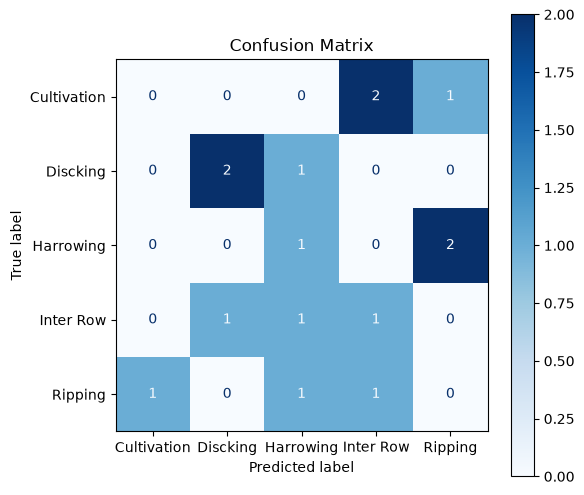


--- Top 5 Important Features ---
1. vvvh__min__mean: 0.1403
2. vv__min__mean: 0.1198
3. vh__min__mean: 0.1150
4. B12__min__mean: 0.0928
5. B08__min__mean: 0.0920


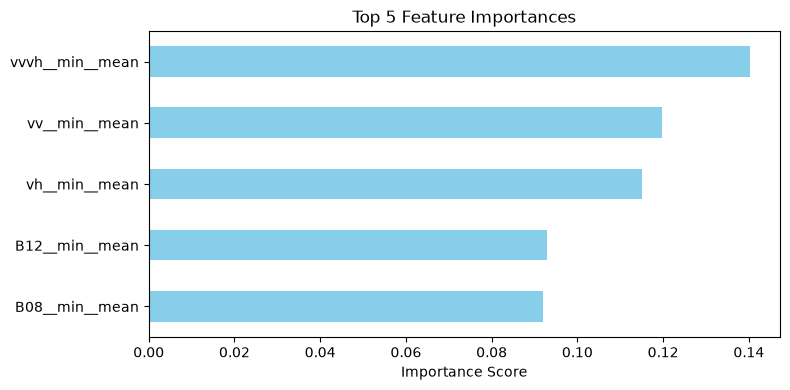

In [ ]:
acc

0.26666666666666666

In [ ]:
# ==============================================================================
# 3. THRESHOLD OPTIMIZATION & VISUALIZATION
# ==============================================================================

if(target_to_use == 'baseline'):
    # Encode target: Conventional = 0, Conservation = 1
    analysis_df["binary_target"] = (analysis_df["Target"].str.lower() == "conservation").astype(int)
elif(target_to_use == 'alex_binary'): 
    #minval = min(analysis_df.Target)
    val = analysis_df.Target.mean()
    analysis_df["binary_target"] =  (analysis_df['Target'] > val).astype(int)
else: 
    raise NotImplementedError 
y_true = analysis_df["binary_target"].values
scores = analysis_df["summary_band"].values

candidate_thresholds = np.linspace(scores.min(), scores.max(), 200)

best_f1_unidirectional, best_acc_unidirectional, best_threshold = -1.0, -1.0, candidate_thresholds[0]
f1_scores, acc_scores = [], []

for t in candidate_thresholds:
    
    if(target_to_use in ['baseline', 'alex_binary']):
        y_pred = (scores >= t).astype(int)
        f1 = f1_score(y_true, y_pred, zero_division=0)
    elif(target_to_use == 'alex'): 

        f1 = f1_score(y_true, y_pred, zero_division=0, average = 'micro') 
    else:
        NotImplementedError
    acc = accuracy_score(y_true, y_pred) 
    f1 = f1 if f1>0.5 else 1-f1 
    acc = acc if acc>0.5 else 1-acc
    
    f1_scores.append(f1)
    acc_scores.append(acc)
    
    #if f1 > best_f1 or (f1 == best_f1 and acc > best_acc):
    if acc > best_acc_unidirectional or (f1 > best_f1_unidirectional and acc == best_acc_unidirectional):
        best_f1_unidirectional, best_acc_unidirectional, best_threshold = f1, acc, t

print("\n================ OPTIMIZATION RESULTS ================")
print(f"Optimal {band} Threshold: {best_threshold:.4f}")
print(f"Maximized F1-Score (Unidirectional):     {best_f1_unidirectional:.4f}")
print(f"Overall Accuracy (Unidirectional):       {best_acc_unidirectional:.4f}")
print("======================================================")

# Plot distributions and optimization curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

conv_scores = analysis_df[analysis_df["binary_target"] == 0]["summary_band"]
cons_scores = analysis_df[analysis_df["binary_target"] == 1]["summary_band"]

label0 , label1 = np.unique(analysis_df['Target'].astype(str))
ax1.hist(conv_scores, bins=15, alpha=0.6, color="orangered", label=label0)
ax1.hist(cons_scores, bins=15, alpha=0.6, color="seagreen", label=label1)
ax1.axvline(best_threshold, color="black", linestyle="--", linewidth=2, label=f"Threshold ({best_threshold:.3f})")
ax1.set_xlabel(f"Summary {band} (Temporal Min → Spatial Mean)")
ax1.set_ylabel("Count")
ax1.set_title(f"{band} Distribution by Tillage Type")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(candidate_thresholds, f1_scores, color="purple", label="F1-Score", linewidth=2)
ax2.plot(candidate_thresholds, acc_scores, color="dodgerblue", label="Accuracy", linewidth=2)
ax2.axvline(best_threshold, color="black", linestyle="--", linewidth=1.5, label="Optimal Cutoff")
ax2.set_xlabel("Candidate Threshold")
ax2.set_ylabel("Score")
ax2.set_title("F1 / Accuracy Optimization Curve")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



NotImplementedError: 

In [ ]:
1/0

In [ ]:
# ==============================================================================
# 3. THRESHOLD OPTIMIZATION & VISUALIZATION -- COPY
# ==============================================================================

if(target_to_use == 'baseline'):
    # Encode target: Conventional = 0, Conservation = 1
    analysis_df["binary_target"] = (analysis_df["Target"].str.lower() == "conservation").astype(int)
elif(target_to_use == 'alex'): 
    minval = min(analysis_df.Target)
    analysis_df["binary_target"] =  analysis_df['binary_target'] - minval  
else: 
    raise NotImplementedError 
y_true = analysis_df["binary_target"].values
scores = analysis_df["summary_band"].values

candidate_thresholds = np.linspace(scores.min(), scores.max(), 200)

best_f1, best_acc, best_threshold = -1.0, -1.0, candidate_thresholds[0]
f1_scores, acc_scores = [], []

for t in candidate_thresholds:
    y_pred = (scores >= t).astype(int)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    
    f1_scores.append(f1)
    acc_scores.append(acc)
    
    #if f1 > best_f1 or (f1 == best_f1 and acc > best_acc):
    if acc > best_acc or (f1 > best_f1 and acc == best_acc):
        best_f1, best_acc, best_threshold = f1, acc, t

print("\n================ OPTIMIZATION RESULTS ================")
print(f"Optimal {band} Threshold: {best_threshold:.4f}")
print(f"Maximized F1-Score:     {best_f1:.4f}")
print(f"Overall Accuracy:       {best_acc:.4f}")
print("======================================================")

# Plot distributions and optimization curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

conv_scores = analysis_df[analysis_df["binary_target"] == 0]["summary_band"]
cons_scores = analysis_df[analysis_df["binary_target"] == 1]["summary_band"]

ax1.hist(conv_scores, bins=15, alpha=0.6, color="orangered", label="Conventional")
ax1.hist(cons_scores, bins=15, alpha=0.6, color="seagreen", label="Conservation")
ax1.axvline(best_threshold, color="black", linestyle="--", linewidth=2, label=f"Threshold ({best_threshold:.3f})")
ax1.set_xlabel(f"Summary {band} (Temporal Min → Spatial Mean)")
ax1.set_ylabel("Count")
ax1.set_title(f"{band} Distribution by Tillage Type")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(candidate_thresholds, f1_scores, color="purple", label="F1-Score", linewidth=2)
ax2.plot(candidate_thresholds, acc_scores, color="dodgerblue", label="Accuracy", linewidth=2)
ax2.axvline(best_threshold, color="black", linestyle="--", linewidth=1.5, label="Optimal Cutoff")
ax2.set_xlabel("Candidate Threshold")
ax2.set_ylabel("Score")
ax2.set_title("F1 / Accuracy Optimization Curve")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()